In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F 
import torch.optim as optim

import torchvision 
import torchvision.transforms as transforms


import matplotlib.pyplot as plt 
import numpy as np 

from torch.utils.tensorboard import SummaryWriter

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,),(0.5,))
])

In [3]:
training_set= torchvision.datasets.FashionMNIST(
    root="./",
    download=True,
    train=True,
    transform=transform
)
validation_set= torchvision.datasets.FashionMNIST(
    root="./",
    download=True,
    train=False,
    transform=transform
)

In [4]:
training_loader= torch.utils.data.DataLoader(training_set, batch_size=4,
shuffle=True, num_workers=2)
validation_loader= torch.utils.data.DataLoader(validation_set, batch_size=4, shuffle=False, num_workers=2)

In [5]:
classes= ("T-shirt/top","Trouser","Pullover","Dress","Coat","Sandal","Shirt","Sneaker","Bag","Ankle Boot")

In [6]:
def matplot_imshow(img, one_channel=False):
    if one_channel:
        img= img.mean(dim=0)
    img= img/2+0.5
    npimg=img.numpy()

    if one_channel:
        plt.imshow(npimg, cmap="Greys")
    else:
        plt.imshow(np.transpose(npimg, (1,2,0)))


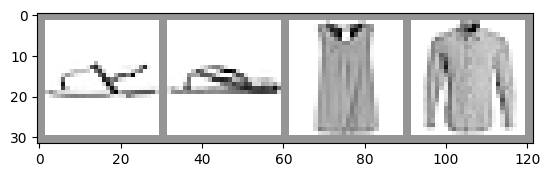

In [7]:
dataiter = iter(training_loader)
images, labels = next(dataiter)

img_grid=torchvision.utils.make_grid(images)
matplot_imshow(img_grid, True)

tensorboard --logdir=runs

In [8]:
writer=SummaryWriter("runs/fashion_mnist_experiment_1")
writer.add_image("Four Fashion Mnist Image", img_grid)
writer.flush()

In [9]:
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()

        self.conv1= nn.Conv2d(1,6,5)
        self.pool= nn.MaxPool2d(2,2)
        self.conv2= nn.Conv2d(6,16,5)
        self.fc1= nn.Linear(16*4*4, 120)
        self.fc2= nn.Linear(120, 84)
        self.fc3= nn.Linear(84, 10)


    def forward(self, x):
        x= self.pool(F.relu(self.conv1(x)))
        x= self.pool(F.relu(self.conv2(x)))
        x= x.view(-1, 16 *4*4)
        x= F.relu(self.fc1(x))
        x= F.relu(self.fc2(x))
        x= self.fc3(x)
        return x

In [10]:
net= Net()
criterion= nn.CrossEntropyLoss()
optimizer=optim.SGD(net.parameters(), lr=0.001, momentum=0.9)

In [11]:
print(len(validation_loader))

for epoch in range(1):
    running_loss=0.0
    for i , data in enumerate(training_loader, 0):
        inputs, labels= data 
        optimizer.zero_grad()
        outputs= net(inputs)

        loss= criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss+=loss.item()
        if i %1000==999:
            print("Batch {}".format(i+1))
            running_vloss= 0.0

            net.train(False)
            for j , vdata in enumerate(validation_loader, 0):
                vinputs, vlabels= vdata
                voutputs= net(vinputs)
                vloss= criterion(voutputs, vlabels)
                running_vloss+=vloss.item()

            net.train(True)
            avg_loss=running_loss/1000
            avg_vloss= running_vloss/len(validation_loader)

            writer.add_scalars("Trainig_loss VS Validation_loss", {
                'training':avg_loss, "validation":avg_vloss,
            },
            epoch*len(training_loader)+i)

            running_loss=0.0

print("Finished Training")
writer.flush()





2500
Batch 1000
Batch 2000
Batch 3000
Batch 4000
Batch 5000
Batch 6000
Batch 7000
Batch 8000
Batch 9000
Batch 10000
Batch 11000
Batch 12000
Batch 13000
Batch 14000
Batch 15000
Finished Training


In [12]:
dataiter= iter(training_loader)
images, labels= next(dataiter)

writer.add_graph(net, images)
writer.flush()

In [13]:
def select_n_random(data, labels, n=100):
    assert len(data) == len(labels)
    perm = torch.randperm(len(data))
    return data[perm][:n], labels[perm][:n]

images, labels = select_n_random(training_set.data, training_set.targets)

classes_labels = [classes[label] for label in labels]
features = images.view(-1, 28 * 28)

writer.add_embedding(
    features,
    metadata=classes_labels,
    label_img=images.unsqueeze(1)
)

writer.flush()


In [14]:
writer.close()       
    